In [42]:
import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency
from sklearn.cluster import KMeans
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (silhouette_score, calinski_harabasz_score,
                             davies_bouldin_score, adjusted_rand_score)
import joblib
import warnings
warnings.filterwarnings('ignore')

In [43]:
SEED = 25223721
for d in ["Figures", "Outputs", "Models"]:
    os.makedirs(d, exist_ok=True)

In [44]:
data = pd.read_csv('Dataset/Final Dataset.csv').drop(columns=['Unnamed: 0']).reset_index(drop = True)
train_idx = pd.read_csv('Dataset/train_idx.csv').iloc[:,0].values
test_idx = pd.read_csv('Dataset/test_idx.csv').iloc[:,0].values

In [45]:
print('Training Data -> ',len(train_idx))
print('Testing Data -> ',len(test_idx))

Training Data ->  190480
Testing Data ->  47621


Columns Needed for K-means


In [46]:
feat = ["Year_of_Construction", "GroundFloorArea(sq m)", "NoStoreys",
        "UValueWall", "UValueRoof", "UValueFloor", "UValueWindow", "InsulationThickness",
        "HSMainSystemEfficiency", "WHMainSystemEff"]
X_tr, X_te = data.loc[train_idx, feat], data.loc[test_idx, feat]

In [47]:
skew = X_tr.skew()
skewed = [c for c in feat if skew[c] > 1 and X_tr[c].min() >= 0]
print('Log transformation will be applied to: ',skewed)

Log transformation will be applied to:  ['GroundFloorArea(sq m)', 'UValueWall', 'UValueRoof', 'HSMainSystemEfficiency', 'WHMainSystemEff']


In [48]:
def log_tf(df):
  df = df.copy()
  df[skewed] = np.log1p(df[skewed])
  return df

imp = SimpleImputer(strategy = 'median').fit(log_tf(X_tr))
A_tr = pd.DataFrame(imp.transform(log_tf(X_tr)),columns = feat,index = X_tr.index)
A_te = pd.DataFrame(imp.transform(log_tf(X_te)),columns = feat,index = X_te.index)

Capping outliers to ensure K-Means work as intended

In [49]:
low,high = A_tr.quantile(0.01),A_tr.quantile(0.99)
A_tr,A_te = A_tr.clip(low,high,axis = 1), A_te.clip(low,high,axis=1)

In [50]:
sc = StandardScaler().fit(A_tr)
Z_tr,Z_te = sc.transform(A_tr), sc.transform(A_te)
print('Training Data: ',Z_tr.shape)
print('Testing Data: ',Z_te.shape)

Training Data:  (190480, 10)
Testing Data:  (47621, 10)


inding the Appropiate K

In [51]:
rows = []
for k in range(2,11):
  km_k = KMeans(n_clusters = k, init = 'k-means++', n_init = 10, random_state = SEED).fit(Z_tr)
  lab = km_k.labels_
  rows.append(
      {
          'K': k,
          'inertia': km_k.inertia_,
          'silhouette':silhouette_score(Z_tr,lab,sample_size = 10000, random_state = SEED),
          'calinski_harabasz':calinski_harabasz_score(Z_tr,lab),
          'davies_bouldin':davies_bouldin_score(Z_tr,lab)
      }
  )
k_table = pd.DataFrame(rows).set_index('K')
print(k_table.round(3))
k_table.to_csv("Outputs/kmeans_k_selection.csv")

        inertia  silhouette  calinski_harabasz  davies_bouldin
K                                                             
2   1257624.496       0.344          98020.274           1.129
3   1035420.964       0.310          79965.920           1.405
4    919010.752       0.263          68105.564           1.514
5    854537.434       0.236          58525.467           1.559
6    809637.152       0.215          51529.318           1.674
7    748990.957       0.199          48988.276           1.681
8    710557.838       0.201          45732.698           1.694
9    674501.924       0.210          43427.699           1.629
10   651816.511       0.206          40682.323           1.630


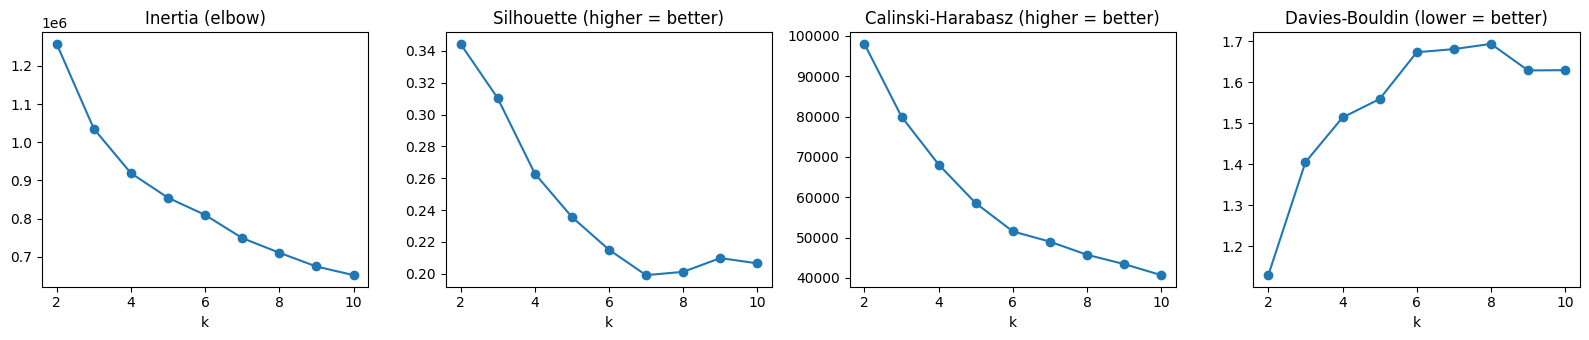

In [52]:
fig, ax = plt.subplots(1, 4, figsize=(16, 3.5))
for a, (col, ttl) in zip(ax, [("inertia", "Inertia (elbow)"), ("silhouette", "Silhouette (higher = better)"),
                              ("calinski_harabasz", "Calinski-Harabasz (higher = better)"),
                              ("davies_bouldin", "Davies-Bouldin (lower = better)")]):
    a.plot(k_table.index, k_table[col], "o-"); a.set(title=ttl, xlabel="k")
plt.tight_layout(); plt.savefig("Figures/kmeans_k_selection.png", dpi=200); plt.show()

Best value for k is 2

In [62]:
K=2
km = KMeans(n_clusters = K, init = 'k-means++',n_init = 10, random_state = SEED).fit(Z_tr)
labels_tr,labels_te = km.labels_, km.predict(Z_te)
sizes = pd.DataFrame({"train_%": pd.Series(labels_tr).value_counts(normalize=True).sort_index() * 100,
                      "test_%": pd.Series(labels_te).value_counts(normalize=True).sort_index() * 100})
print(sizes.round(1))

   train_%  test_%
0     70.3    70.3
1     29.7    29.7


In [63]:
rng = np.random.default_rng(SEED)
ari_seed = [adjusted_rand_score(labels_tr, KMeans(n_clusters=K, n_init=10, random_state=s).fit_predict(Z_tr))
            for s in range(1, 6)]
ari_sub = []
for _ in range(5):
    sub = rng.choice(len(Z_tr), len(Z_tr) // 2, replace=False)
    ks = KMeans(n_clusters=K, n_init=10, random_state=SEED).fit(Z_tr[sub])
    ari_sub.append(adjusted_rand_score(labels_tr, ks.predict(Z_tr)))
print(f"ARI across random seeds:      {np.mean(ari_seed):.3f}")
print(f"ARI across half-sample fits:  {np.mean(ari_sub):.3f}")

ARI across random seeds:      1.000
ARI across half-sample fits:  0.999


In [64]:
tr = data.loc[train_idx].copy()
tr['cluster'] = labels_tr
tr['era'] = pd.cut(tr['Year_of_Construction'],[0,1950,1970,1980,1990,2000,2010,2100]).astype(str)

def eta2(y, g):
    y = pd.Series(np.asarray(y, dtype=float)); g = pd.Series(np.asarray(g).astype(str))
    return ((y.groupby(g).transform("mean") - y.mean()) ** 2).sum() / ((y - y.mean()) ** 2).sum()

for t in ["BerRating", "CO2Rating"]:
    print(f"{t}: share of variance explained -> clusters (k={K}): {eta2(tr[t], tr['cluster']):.3f} | "
          f"7 construction-era bands: {eta2(tr[t], tr['era']):.3f}")

BerRating: share of variance explained -> clusters (k=2): 0.497 | 7 construction-era bands: 0.485
CO2Rating: share of variance explained -> clusters (k=2): 0.501 | 7 construction-era bands: 0.477


In [65]:
prof = tr.groupby('cluster')[feat].median()
prof.insert(0,'size_%',(tr["cluster"].value_counts(normalize=True).sort_index() * 100).round(1))
prof['BeRating_mean'] = tr.groupby('cluster')['BerRating'].mean()
prof['CO2Rating_mean'] = tr.groupby('cluster')['CO2Rating'].mean()
print(prof.round(2).T)
prof.to_csv("Outputs/kmeans_cluster_profiles.csv")

cluster                       0        1
size_%                    70.30    29.70
Year_of_Construction    1992.00  2025.00
GroundFloorArea(sq m)    117.84   105.48
NoStoreys                  2.00     2.00
UValueWall                 0.55     0.18
UValueRoof                 0.26     0.13
UValueFloor                0.44     0.14
UValueWindow               2.44     1.20
InsulationThickness       30.00     0.00
HSMainSystemEfficiency    90.60   448.01
WHMainSystemEff           90.70   250.88
BeRating_mean            177.78    39.02
CO2Rating_mean            38.58     5.30


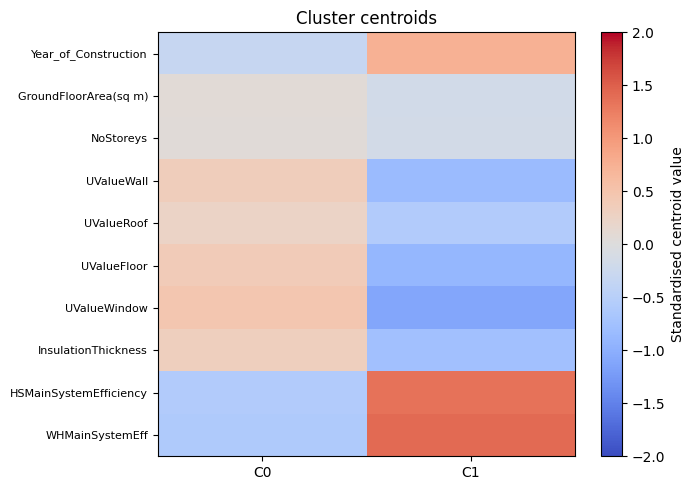

In [66]:
plt.figure(figsize=(7, 5))
plt.imshow(km.cluster_centers_.T, cmap="coolwarm", vmin=-2, vmax=2, aspect="auto")
plt.xticks(range(K), [f"C{i}" for i in range(K)]); plt.yticks(range(len(feat)), feat, fontsize=8)
plt.colorbar(label="Standardised centroid value"); plt.title("Cluster centroids")
plt.tight_layout(); plt.savefig("Figures/kmeans_centroids.png", dpi=200); plt.show()

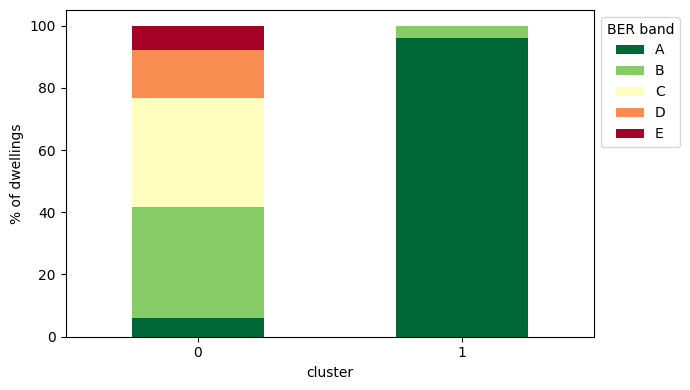

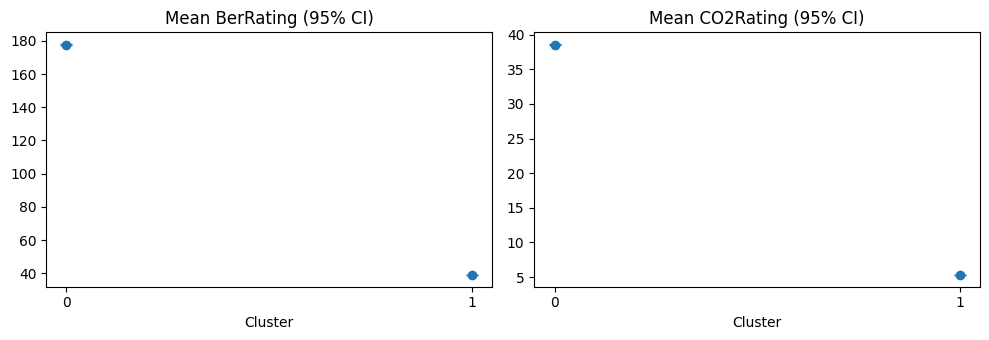

In [67]:
tr["band"] = tr["EnergyRating"].astype(str).str[0]
ct = (pd.crosstab(tr["cluster"], tr["band"], normalize="index") * 100)
ct.plot(kind="bar", stacked=True, figsize=(7, 4), colormap="RdYlGn_r")
plt.ylabel("% of dwellings"); plt.legend(title="BER band", bbox_to_anchor=(1, 1)); plt.xticks(rotation=0)
plt.tight_layout(); plt.savefig("Figures/kmeans_rating_mix.png", dpi=200); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
for a, t in zip(ax, ["BerRating", "CO2Rating"]):
    g = tr.groupby("cluster")[t]
    a.errorbar(g.mean().index, g.mean(), yerr=1.96 * g.std() / np.sqrt(g.count()), fmt="o", capsize=4)
    a.set(title=f"Mean {t} (95% CI)", xlabel="Cluster"); a.set_xticks(range(K))
plt.tight_layout(); plt.savefig("Figures/kmeans_ber_co2_by_cluster.png", dpi=200); plt.show()

CountyName: Cramer's V = 0.115, p = 0
DwellingTypeDescr: Cramer's V = 0.259, p = 0
MainSpaceHeatingFuel: Cramer's V = 0.820, p = 0


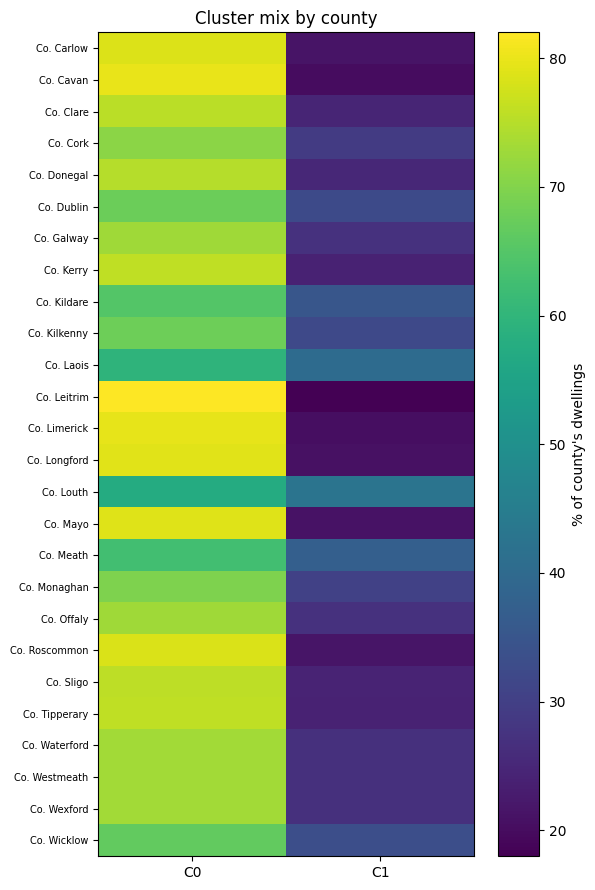

DwellingTypeDescr  Apartment  Basement Dwelling  Detached house  \
cluster                                                           
0                        0.0                0.0            41.5   
1                        0.0                0.1            22.4   

DwellingTypeDescr  End of terrace house  Ground-floor apartment  Maisonette  \
cluster                                                                       
0                                   6.0                     3.6         0.9   
1                                  10.3                     7.1         2.7   

DwellingTypeDescr  Mid-floor apartment  Mid-terrace house  \
cluster                                                     
0                                  4.7               11.8   
1                                 14.4               12.5   

DwellingTypeDescr  Semi-detached house  Top-floor apartment  
cluster                                                      
0                                 27.5       

In [68]:
for c in ["CountyName", "DwellingTypeDescr", "MainSpaceHeatingFuel"]:
    tr[c] = tr[c].astype(str).str.strip()

def cramers_v(table):
    chi2_, p_, _, _ = chi2_contingency(table)
    return np.sqrt((chi2_ / table.values.sum()) / min(table.shape[0] - 1, table.shape[1] - 1)), p_

for c in ["CountyName", "DwellingTypeDescr", "MainSpaceHeatingFuel"]:
    v, p_ = cramers_v(pd.crosstab(tr["cluster"], tr[c]))
    print(f"{c}: Cramer's V = {v:.3f}, p = {p_:.3g}")

county_mix = pd.crosstab(tr["CountyName"], tr["cluster"], normalize="index") * 100
county_mix.to_csv("Outputs/kmeans_county_mix.csv")
plt.figure(figsize=(6, 9))
plt.imshow(county_mix, cmap="viridis", aspect="auto")
plt.xticks(range(K), [f"C{i}" for i in range(K)]); plt.yticks(range(len(county_mix)), county_mix.index, fontsize=7)
plt.colorbar(label="% of county's dwellings"); plt.title("Cluster mix by county")
plt.tight_layout(); plt.savefig("Figures/kmeans_county_mix.png", dpi=200); plt.show()

print(pd.crosstab(tr["cluster"], tr["DwellingTypeDescr"], normalize="index").mul(100).round(1))
print(pd.crosstab(tr["cluster"], tr["MainSpaceHeatingFuel"], normalize="index").mul(100).round(1))

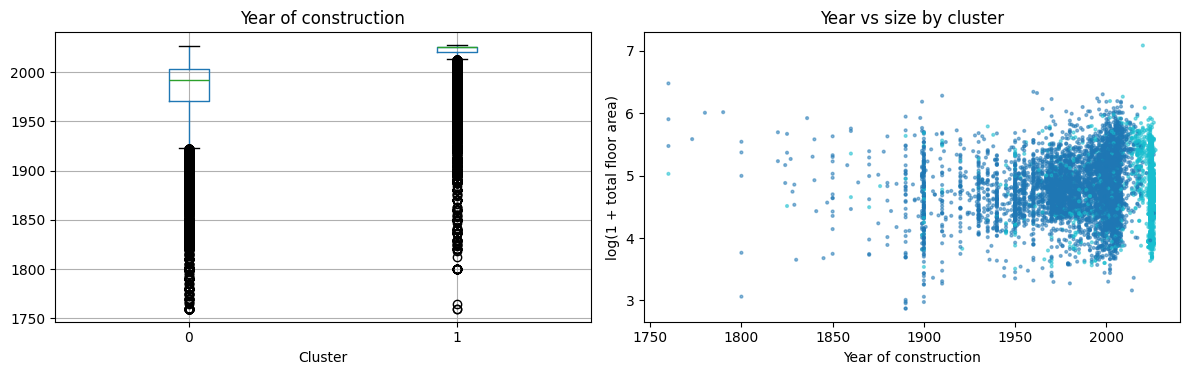

In [69]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
tr.boxplot(column="Year_of_Construction", by="cluster", ax=ax[0]); ax[0].set(title="Year of construction", xlabel="Cluster")
s = rng.choice(len(tr), min(8000, len(tr)), replace=False)
ax[1].scatter(tr["Year_of_Construction"].values[s], np.log1p(tr["GroundFloorArea(sq m)"].values[s]),
              c=tr["cluster"].values[s], cmap="tab10", s=4, alpha=0.5)
ax[1].set(xlabel="Year of construction", ylabel="log(1 + total floor area)", title="Year vs size by cluster")
plt.suptitle(""); plt.tight_layout(); plt.savefig("Figures/kmeans_year_size.png", dpi=200); plt.show()

In [70]:
pd.Series(labels_tr, index=train_idx, name="cluster").to_csv("Outputs/kmeans_labels_train.csv")
pd.Series(labels_te, index=test_idx, name="cluster").to_csv("Outputs/kmeans_labels_test.csv")
joblib.dump({"km": km, "imp": imp, "scaler": sc, "lo": low, "hi": high, "skewed": skewed, "feat": feat, "K": K},
            "Models/kmeans_pipeline.joblib")

['Models/kmeans_pipeline.joblib']